### <b>5강 꾸미기와 여러 그래프 - 색·마커 · 축과 주석 · subplots · savefig</b>

* 강조할 것 하나만 색을 다르게 하고 나머지는 회색으로 둔다. <b>color</b>·<b>marker</b>·<b>linestyle</b>·<b>linewidth</b>로 선과 막대를 다듬는다.
* <b>tick_params</b>로 눈금 글자를 기울이고, <b>set_ylim</b>·<b>axhline</b>·<b>annotate</b>로 기준선과 설명을 달아 읽는 사람의 시선을 이끈다.
* <b>subplots</b>로 여러 그래프를 한 Figure에 나란히 놓고, <b>savefig</b>로 해상도와 여백을 정해 파일로 저장한다.

* 첫 코드 셀은 매 시간 실행하는 <b>설정 셀</b>이다. 1강에서 정한 그대로다.

In [1]:
# keep
# 설명: 매 차시 같은 설정 셀이다. 출력이 없는 것이 정상이다.
# 설명: rcParams는 커널이 켜져 있는 동안만 유지된다. 커널을 다시 시작했다면 이 셀부터 실행한다.
# 설명: 뒤에서 그래프 글자가 □로 나오면 이 셀을 실행했는지부터 확인하게 한다.
import platform
import pandas as pd
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

* 오늘도 두 파일을 모두 쓴다. 2강과 같은 방법으로 읽는다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 365일 판매(가상), 하루 = 1행. date 열은 날짜로 읽는다.

In [2]:
# keep
# 설명: 출력 (300, 12) (365, 14)로 두 파일의 행과 열을 확인한다.
# 설명: parse_dates를 짚는다. date가 날짜 값이어야 3)에서 눈금을 매달 1일로 정할 수 있다.
# 설명: FileNotFoundError가 나면 경로를 본다. ../는 노트북 폴더의 한 단계 위다.
students = pd.read_csv('../data/students.csv')
cafe = pd.read_csv('../data/cafe_sales.csv', parse_dates=['date'])
print(students.shape, cafe.shape)

(300, 12) (365, 14)


#### <b>1) 메뉴별 판매량 선 그래프에서 아메리카노만 강조</b>

* 3강에서 메뉴 네 개의 일별 판매량을 겹쳐 그렸다. 하루 단위라 선이 촘촘했다.
* 이번에는 <b>groupby</b>로 월마다 메뉴별 판매 잔 수를 더해 12개 값만 남긴다.
  * 열 네 개를 한꺼번에 더하므로 결과는 <b>DataFrame</b>이다. index는 월(year_month), 열은 메뉴다.

In [3]:
# 설명: 실행 전에 예고한다. 365행이 12행으로 줄어든다.
# 설명: 대괄호가 두 겹인 곳이 막히기 쉽다. 바깥은 열 고르기, 안쪽은 열 이름 리스트다.
# 설명: 출력에서 americano 열의 4793(2025-04)과 1454(2026-02)를 찾아 둔다. 다음 그래프에서 같은 값을 다시 본다.
menu_by_month = cafe.groupby('year_month')[['americano', 'latte', 'ade', 'tea']].sum()
menu_by_month

,americano,latte,ade,tea
year_month,,,,
2025-03,4573,2880,1660,1342
2025-04,4793,2697,2475,1151
2025-05,4410,2179,2399,817
2025-06,4046,1854,2611,611
2025-07,1939,753,1559,180
2025-08,1878,695,1567,172
2025-09,4220,1721,3173,486
2025-10,4086,2273,2021,1011
2025-11,3864,2396,1563,1179


* 먼저 3강처럼 기본 색으로 그린다. 선 네 개가 파랑·주황·초록·빨강으로 모두 비슷하게 눈에 띈다.
  * 무엇을 보라는 그래프인지 그래프만 보고는 알기 어렵다.

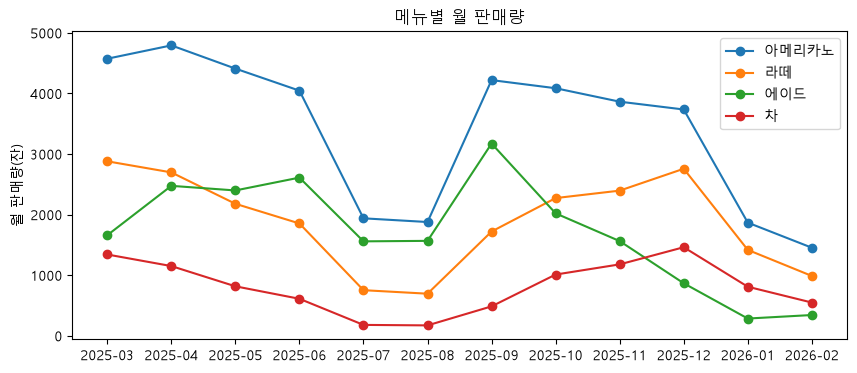

In [4]:
# 설명: 다음 셀과 비교할 강조 전 그림이다. 일부러 기본 색 그대로 그린다.
# 설명: 실행 후 이 그래프의 결론이 무엇인지 묻는다. 답이 바로 나오지 않는 것이 이 셀의 요점이다.
# 설명: 제목도 '메뉴별 월 판매량'이라 내용 소개뿐이다. 다음 셀 제목과 비교할 곳으로 짚어 둔다.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(menu_by_month.index, menu_by_month['americano'], marker='o', label='아메리카노')
ax.plot(menu_by_month.index, menu_by_month['latte'], marker='o', label='라떼')
ax.plot(menu_by_month.index, menu_by_month['ade'], marker='o', label='에이드')
ax.plot(menu_by_month.index, menu_by_month['tea'], marker='o', label='차')
ax.set_title('메뉴별 월 판매량')
ax.set_ylabel('월 판매량(잔)')
ax.legend()
plt.show()

* 선의 모양은 plot 안에 인자로 정한다.
  * <b>color</b>: 색. 이름('lightgray', 'tab:blue')이나 <b>HEX</b> 코드('#d62728', 빨강·초록·파랑 세기를 16진수 두 자리씩 적은 색 번호)로 쓴다.
  * <b>marker</b>: 값 자리의 점 모양. 'o' 동그라미, 's' 네모, '^' 세모
  * <b>linestyle</b>: 선 모양. '-' 실선, '--' 끊은 선, ':' 점선, '-.' 점·선
  * <b>linewidth</b>: 선 굵기. 기본 1.5
  * <b>alpha</b>: 4강 산점도에서 본 투명도. 선에도 똑같이 쓴다.
* 강조 원칙: 보여 줄 선 하나만 진한 색·굵은 선으로, 나머지는 회색으로 둔다.
  * 회색 선 세 개는 linestyle을 다르게 해서 범례로 구분한다.
  * 아메리카노를 마지막에 그려 회색 선 위에 올라오게 한다.
  * 제목에 그래프가 말하려는 결론을 쓴다.

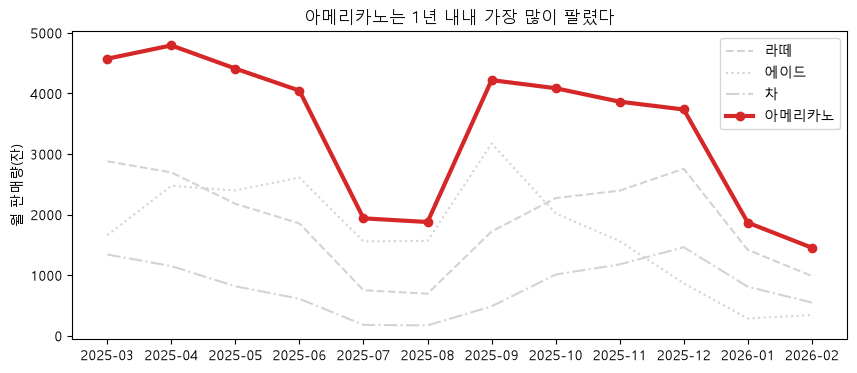

In [5]:
# 설명: 앞 셀과 같은 데이터를 쓴다. 코드에서 달라진 곳을 color, linestyle, linewidth 순서로 짚는다.
# 설명: americano 줄이 첫 줄에서 마지막 줄로 내려온 것도 보여 준다. 그래서 범례에서도 맨 아래로 간다.
# 설명: 실행 후 앞 그래프와 번갈아 보며 눈이 어디로 먼저 가는지 묻는다.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(menu_by_month.index, menu_by_month['latte'], color='lightgray', linestyle='--', label='라떼')
ax.plot(menu_by_month.index, menu_by_month['ade'], color='lightgray', linestyle=':', label='에이드')
ax.plot(menu_by_month.index, menu_by_month['tea'], color='lightgray', linestyle='-.', label='차')
ax.plot(menu_by_month.index, menu_by_month['americano'], color='#d62728', marker='o', linewidth=3, label='아메리카노')
ax.set_title('아메리카노는 1년 내내 가장 많이 팔렸다')
ax.set_ylabel('월 판매량(잔)')
ax.legend()
plt.show()

* 그래프에서 읽을 것
  * 빨간 아메리카노 선이 12개월 모두 맨 위에 있다. 가장 많은 달은 2025-04(4,793잔), 가장 적은 달은 2026-02(1,454잔)다.
  * 회색 선은 배경으로 물러나고, 눈이 빨간 선을 먼저 따라간다. 데이터는 그대로이고 색만 바꿨다.

#### <b>2) 전공별 학생 수 막대에서 가장 큰 막대만 강조</b>

* 4강의 정렬한 전공별 학생 수를 다시 만든다. 작은 값부터 정렬되어 공학(80명)이 마지막에 있다.

In [6]:
# 설명: 이 노트북에는 아직 이 변수가 없어서 4강의 값을 다시 만든다.
# 설명: 출력은 예체능 40부터 공학 80까지 오름차순이다. 인문과 자연과학은 55로 같다.
# 설명: 작은 값부터 정렬한 이유는 barh가 아래부터 막대를 놓기 때문이다. 공학이 맨 위로 간다.
major_count_sorted = students['major'].value_counts().sort_values()
major_count_sorted

major
예체능     40
인문      55
자연과학    55
사회과학    70
공학      80
Name: count, dtype: int64

* 막대는 <b>color</b>에 색 하나를 넣으면 모든 막대가 그 색이 되고, 색 <b>리스트</b>를 넣으면 막대마다 색이 따로 칠해진다.
  * 리스트 순서는 막대 순서와 같아야 한다.
* 가장 큰 값만 빨강, 나머지는 회색인 리스트를 만든다.
  * <b>[A if 조건 else B for v in 값들]</b>: 값을 하나씩 꺼내 조건이 맞으면 A, 아니면 B를 담는 파이썬 리스트 문법이다.
  * 조건을 '공학'이 아니라 <b>max()</b>로 써 두면 데이터가 바뀌어도 가장 큰 막대가 칠해진다.

In [7]:
# 설명: 한 줄이 길어 막히기 쉬운 셀이다. v에 40과 80을 넣어 소리 내어 읽어 준다.
# 설명: 출력은 다섯 칸 리스트이고 마지막만 '#d62728'이다. 공학이 정렬의 마지막이기 때문이다.
# 설명: 이 colors는 다음 셀과 5)의 왼쪽 칸에서 다시 쓴다.
colors = ['#d62728' if v == major_count_sorted.max() else 'lightgray' for v in major_count_sorted.values]
colors

['lightgray', 'lightgray', 'lightgray', 'lightgray', '#d62728']

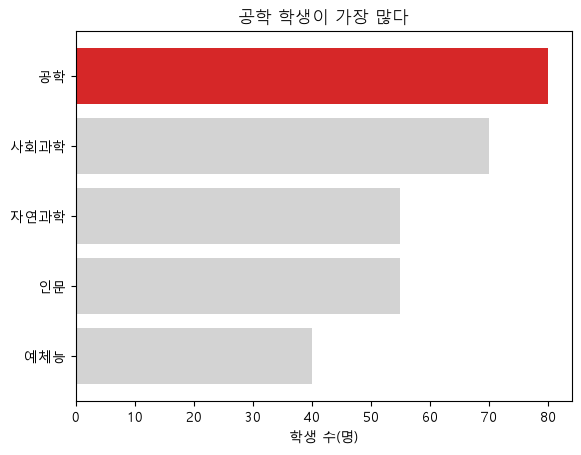

In [8]:
# 설명: color=colors만 짚으면 된다. 앞 셀에서 만든 리스트를 그대로 넣는다.
# 설명: 실행 전에 어느 막대가 빨개질지 묻는다. 리스트의 마지막 색이 barh에서는 맨 위 막대가 된다.
# 설명: 제목도 1)처럼 결론으로 썼다. NameError가 나면 앞 셀을 실행했는지 본다.
fig, ax = plt.subplots()
ax.barh(major_count_sorted.index, major_count_sorted.values, color=colors)
ax.set_title('공학 학생이 가장 많다')
ax.set_xlabel('학생 수(명)')
plt.show()

* 맨 위 공학(80명) 막대만 빨갛고 나머지 네 막대는 회색이다.
* 막대 길이는 4강과 같다. 색은 순위를 바꾸지 않고, 어디를 먼저 볼지만 정한다.

#### <b>3) 일별 손님 수 그래프에 평균선과 시험 주간 주석 달기</b>

* 먼저 3강에서 남긴 문제부터 푼다. 기본 크기 종이에 월별 평균 손님 수를 그리면 x축 글자 12개가 겹쳤다.
* <b>ax.tick_params(axis='x', labelrotation=45)</b>: x축 눈금 글자를 45도 기울인다. 종이를 넓히지 않고도 글자가 겹치지 않는다.

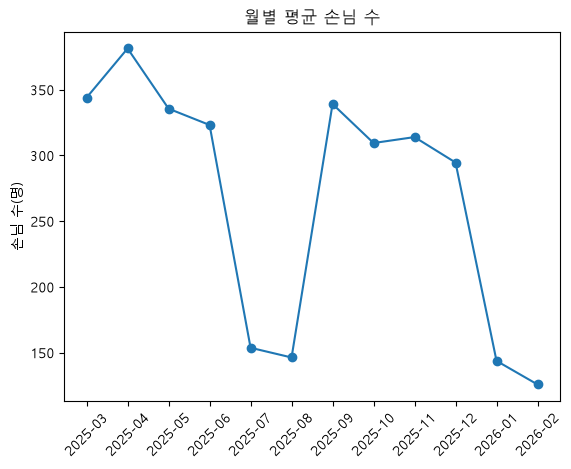

In [9]:
# 설명: 1)은 합계(sum), 이 셀은 평균(mean)이다. 손님 수는 월별 평균으로 본다.
# 설명: figsize를 쓰지 않아 종이는 기본 크기 그대로다. tick_params 한 줄이 무엇을 바꾸는지만 본다.
# 설명: 실행 후 가장 높은 달 2025-04(381.37명)와 가장 낮은 달 2026-02(125.79명)를 짚는다.
# 설명: x값 year_month는 글자다. 다음 셀의 날짜 x축과 대비할 곳이다.
customers_by_month = cafe.groupby('year_month')['customers'].mean().round(2)

fig, ax = plt.subplots()
ax.plot(customers_by_month.index, customers_by_month.values, marker='o')
ax.tick_params(axis='x', labelrotation=45)
ax.set_title('월별 평균 손님 수')
ax.set_ylabel('손님 수(명)')
plt.show()

* 날짜(datetime) x축은 matplotlib이 눈금 자리와 글자 모양을 저절로 정한다. 직접 정하려면 <b>matplotlib.dates</b>를 쓴다.
  * <b>mdates.MonthLocator()</b>: 눈금을 매달 1일에 하나씩 놓는다. <b>MonthLocator(interval=2)</b>는 두 달마다.
  * <b>mdates.DateFormatter('%Y-%m')</b>: 눈금 글자를 '2025-03' 모양으로 쓴다. %Y는 연도 네 자리, %m은 월 두 자리다.
  * <b>ax.xaxis</b>: Axes의 x축(Axis)이다. 3강에서 본 Axes 안의 축 객체에 눈금 규칙을 넘긴다.

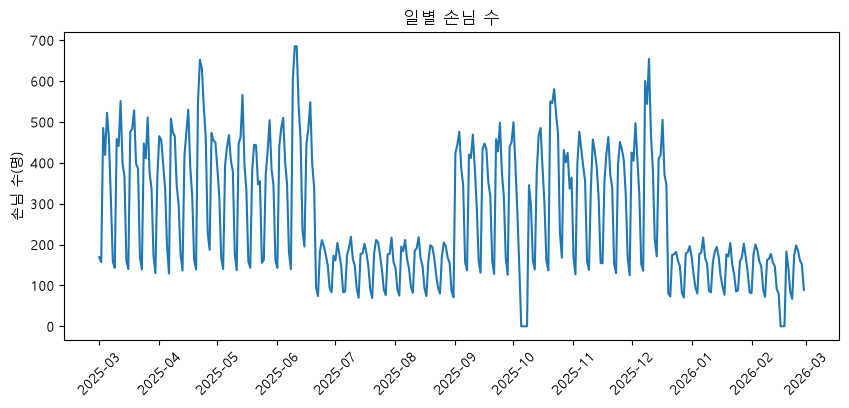

In [10]:
# 설명: 앞 셀과 달리 x값이 date, 날짜 값이다. 날짜 축이라서 mdates로 눈금을 정할 수 있다.
# 설명: mdates는 여기서 처음 불러온다. 이 셀을 건너뛰면 뒤 주석 그래프에서 NameError가 난다.
# 설명: 실행 후 선이 0에 닿는 곳을 찾게 한다. 2025-10 휴무 4일과 2026-02 휴무 3일이다.
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cafe['date'], cafe['customers'])
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.tick_params(axis='x', labelrotation=45)
ax.set_title('일별 손님 수')
ax.set_ylabel('손님 수(명)')
plt.show()

* 눈금이 매달 1일에 하나씩, 2025-03부터 2026-03까지 놓인다. 마지막 2026-03 눈금은 마지막 날(2026-02-28) 바로 뒤, 오른쪽 끝 근처에 놓인다.
  * 글자가 year_month 열과 같은 모양이라 월별 그래프와 함께 읽기 쉽다.
* 이제 주석을 달 자리를 찾는다. 2강의 조건 필터로 시험 주간(exam_week == 1)만 골라 손님이 많은 순으로 본다.

In [11]:
# 설명: 주석을 달 자리를 눈대중이 아니라 데이터로 찾는 단계다.
# 설명: exam은 시험 주간 4주, 28행이다. head(3)로 위 세 줄만 본다.
# 설명: 출력 위 두 줄이 685로 같고, 세 번째는 2025-12-10의 654명이다.
# 설명: 왼쪽 101, 102, 284는 정렬 전 원래 행 번호다. 순서 번호로 읽지 않게 한다.
exam = cafe[cafe['exam_week'] == 1]
exam.sort_values('customers', ascending=False)[['date', 'weekday', 'customers']].head(3)

,date,weekday,customers
101,2025-06-10,화,685
102,2025-06-11,수,685
284,2025-12-10,수,654


* 2025-06-10과 06-11이 둘 다 685명으로 1년 중 가장 많다. 6월 기말시험 주간이다.
  * 이틀이 같은 값이라 '가장 많은 날'은 하나로 정해지지 않는다. 화살표는 둘 중 하루(06-10)를 가리키게 하고, 설명 글에는 날짜 대신 '기말시험 주간'이라고 쓴다.
* 그래프에 기준과 설명을 더한다.
  * <b>ax.set_ylim(0, 800)</b>: y축 범위를 0~800으로 정한다. 아래 기준을 0으로 고정하고, 위에 주석 글자가 들어갈 자리를 만든다.
  * <b>ax.axhline(값)</b>: 그 값 높이에 가로선을 긋는다. 여기서는 365일 평균 손님 수(휴무일 0명 포함 267.95명)다.
  * <b>ax.annotate('글', xy=점 위치, xytext=글 위치, arrowprops=...)</b>: 점 위치에 화살표를 대고 글을 단다.
    * <b>textcoords='offset points'</b>: xytext를 점에서 얼마나 떨어뜨릴지 포인트(약 1/72인치) 단위로 적는다. 날짜 축에서도 숫자 두 개로 쓸 수 있어 편하다.
    * <b>arrowprops=dict(arrowstyle='->')</b>: 글에서 점까지 화살표를 그린다. dict(arrowstyle='->')는 {'arrowstyle': '->'} 사전을 만드는 다른 쓰는 법이다.
    * <b>pd.Timestamp('2025-06-10')</b>: 글자를 날짜 값으로 바꿔 x 위치로 쓴다.

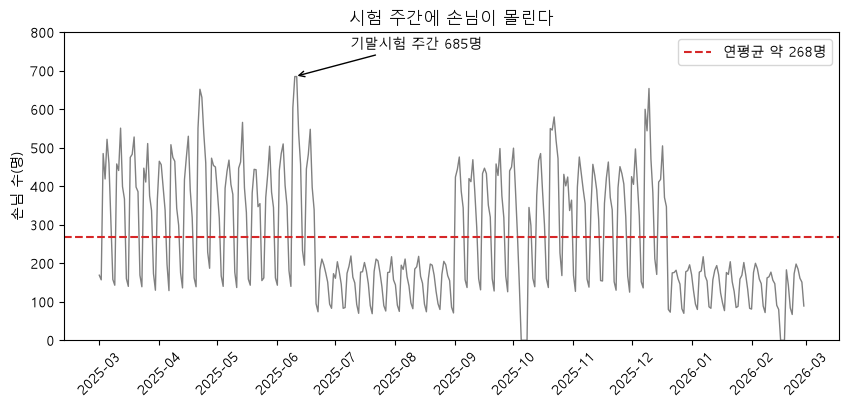

In [12]:
# 설명: 앞 셀에서 찾은 685를 코드에 적는다. 앞 일별 그래프에 기준선과 주석을 더한 그림이다.
# 설명: 빨간 점선의 높이는 mean()이 계산하고, 범례의 '약 268명'은 손으로 쓴 글자다. 둘을 구분해 준다.
# 설명: 평균 약 268명에는 휴무일 7일의 0명이 들어 있다.
# 설명: 실행 후 화살표 끝이 첫 번째 봉우리가 아니라 6월 봉우리에 닿는지 확인한다.
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(cafe['date'], cafe['customers'], color='gray', linewidth=1)
ax.set_ylim(0, 800)
ax.axhline(cafe['customers'].mean(), color='#d62728', linestyle='--', label='연평균 약 268명')
# 설명: xy는 데이터 위치, xytext=(40, 20)은 그 점에서 오른쪽 40, 위로 20포인트다. 단위가 다른 것을 짚는다.
ax.annotate('기말시험 주간 685명', xy=(pd.Timestamp('2025-06-10'), 685),
            xytext=(40, 20), textcoords='offset points',
            arrowprops=dict(arrowstyle='->'))
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.tick_params(axis='x', labelrotation=45)
ax.set_title('시험 주간에 손님이 몰린다')
ax.set_ylabel('손님 수(명)')
ax.legend(loc='upper right')
plt.show()

* 그래프에서 읽을 것
  * 빨간 점선(연평균 약 268명)을 기준으로 학기 평일은 위, 주말·방학은 아래에 있다.
  * 1년 중 600명 이상인 날은 7일뿐이고, 모두 시험 주간이다. 시험 주간 네 번(4·6·10·12월) 모두 선이 뾰족하게 솟고, 600명 이상인 날은 4·6·12월에만 있다.
  * 화살표와 글이 6월 기말시험 주간 봉우리를 가리켜, 그래프를 처음 보는 사람도 어디를 봐야 하는지 안다.

#### <b>4) 메뉴 4개 판매량을 2×2로 나란히</b>

* 3강에서 <b>Figure는 종이, Axes는 칸</b>이라고 했다. 지금까지는 종이 한 장에 칸 하나였다.
* <b>plt.subplots(행, 열)</b>: 종이 한 장을 행×열 칸으로 나눈다. 칸이 여러 개면 두 번째 값은 Axes 하나가 아니라 Axes를 담은 <b>배열</b>이다.
  * 그래서 이름도 ax 대신 <b>axes</b>로 쓴다. <b>axes.shape</b>로 칸 배치를 확인한다.

(2, 2)


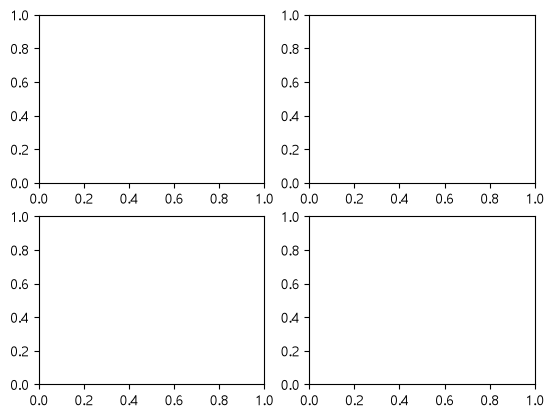

In [13]:
# 설명: 그래프 없이 칸만 먼저 만든다. 그림이 비어 있는 것이 정상이다.
# 설명: 출력 (2, 2)는 2행 2열이다. axes가 배열이라는 증거다.
# 설명: 앞에서처럼 axes.plot을 바로 부르면 AttributeError가 난다. 칸을 먼저 골라야 한다.
fig, axes = plt.subplots(2, 2)
print(axes.shape)
plt.show()

* 칸은 <b>axes[행, 열]</b>로 고른다. 번호는 0부터 센다.
  * axes[0, 0] 왼쪽 위, axes[0, 1] 오른쪽 위, axes[1, 0] 왼쪽 아래, axes[1, 1] 오른쪽 아래
* 고른 칸에 지금까지처럼 plot·set_title을 부른다. 1)의 menu_by_month에서 메뉴 하나씩 칸에 그린다.

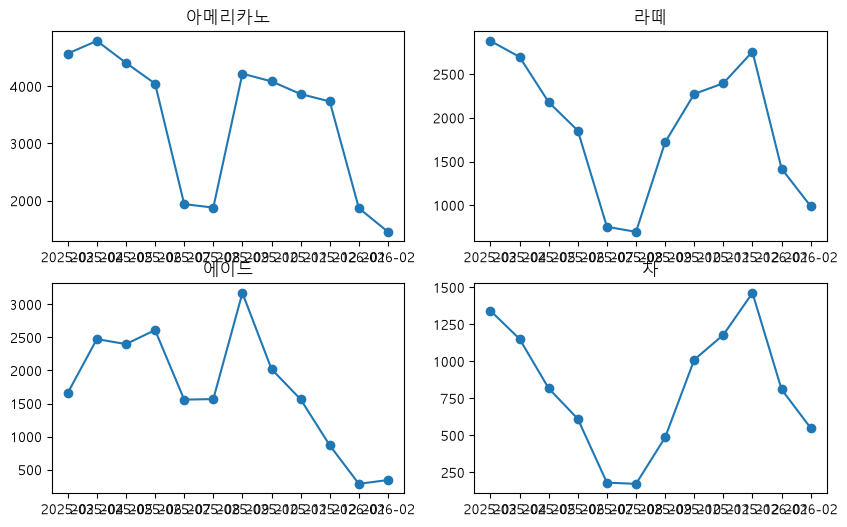

In [14]:
# 설명: 코드가 길어 보이지만 두 줄씩 네 번 반복이다. 칸 번호와 메뉴 이름만 바뀐다.
# 설명: menu_by_month는 1)에서 만들었다. NameError가 나면 그 셀을 실행했는지 본다.
# 설명: 실행 후 바로 고치지 않고 학생에게 어디가 이상한지 먼저 찾게 한다. y축 눈금부터 보게 한다.
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
axes[0, 0].plot(menu_by_month.index, menu_by_month['americano'], marker='o')
axes[0, 0].set_title('아메리카노')
axes[0, 1].plot(menu_by_month.index, menu_by_month['latte'], marker='o')
axes[0, 1].set_title('라떼')
axes[1, 0].plot(menu_by_month.index, menu_by_month['ade'], marker='o')
axes[1, 0].set_title('에이드')
axes[1, 1].plot(menu_by_month.index, menu_by_month['tea'], marker='o')
axes[1, 1].set_title('차')
plt.show()

* 문제가 세 가지 보인다.
  * 칸마다 y축 범위가 다르다. 차 칸은 y축 맨 위가 1,500, 아메리카노 칸은 4,000을 넘는데도 차 선이 아메리카노 선만큼 크게 오르내리는 것처럼 보인다.
  * x축 글자 12개가 칸마다 겹친다.
  * 위 칸의 x축 글자가 아래 칸 제목과 붙는다.
* 고치는 인자
  * <b>sharey=True</b>: 모든 칸이 y축 범위를 같이 쓴다. 칸끼리 높이를 그대로 비교할 수 있다.
  * <b>sharex=True</b>: x축을 같이 쓴다. 겹치는 눈금 글자는 맨 아래 칸에만 남는다.
  * <b>layout='constrained'</b>: 제목·눈금 글자가 겹치지 않게 칸 사이 간격을 저절로 맞춘다.
  * <b>fig.suptitle('제목')</b>: 칸 전체 위에 Figure 제목을 단다.

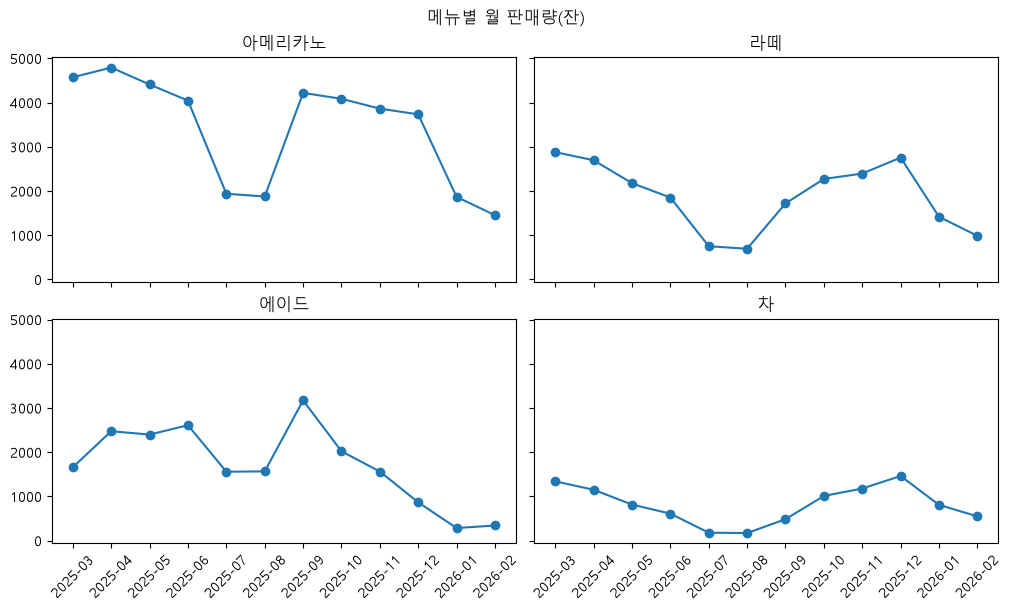

In [15]:
# 설명: 앞 셀 코드에 인자 세 개와 끝의 세 줄만 더했다. 칸마다 그리는 줄은 그대로다.
# 설명: 실행 후 앞 그림과 비교한다. 같은 차 선이 y축을 공유하자 낮게 내려앉는다.
# 설명: set_ylabel 없이 fig.suptitle의 (잔)으로 단위를 한 번만 적었다.
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout='constrained')
axes[0, 0].plot(menu_by_month.index, menu_by_month['americano'], marker='o')
axes[0, 0].set_title('아메리카노')
axes[0, 1].plot(menu_by_month.index, menu_by_month['latte'], marker='o')
axes[0, 1].set_title('라떼')
axes[1, 0].plot(menu_by_month.index, menu_by_month['ade'], marker='o')
axes[1, 0].set_title('에이드')
axes[1, 1].plot(menu_by_month.index, menu_by_month['tea'], marker='o')
axes[1, 1].set_title('차')
# 설명: sharex로 위 칸의 눈금 글자가 사라지므로 아래 두 칸만 기울인다.
axes[1, 0].tick_params(axis='x', labelrotation=45)
axes[1, 1].tick_params(axis='x', labelrotation=45)
fig.suptitle('메뉴별 월 판매량(잔)')
plt.show()

* 그래프에서 읽을 것
  * 네 칸의 y축이 0~5,000 근처로 같아졌다. 아메리카노가 가장 높고, 차는 가장 많은 달(2025-12, 1,462잔)도 아메리카노의 가장 적은 달(2026-02, 1,454잔)과 비슷한 높이다.
  * 에이드는 9월(3,173잔)에 가장 높고 1월(285잔)에 가장 낮다. 차는 12월에 가장 높고 8월(172잔)에 가장 낮다. 계절에 따라 반대로 움직인다.
* 칸마다 범위가 다르면 모양(언제 오르내리는지)을, 범위가 같으면 크기(얼마나 많은지)를 비교하기 좋다. 무엇을 비교할지에 따라 sharey를 고른다.

#### <b>5) 막대·산점도·히스토그램을 1×3으로 한 장에</b>

* 4강의 세 그래프를 종이 한 장에 나란히 놓는다. 수면 시간은 4강처럼 빈 값을 빼 둔다.

In [16]:
# 설명: 빈 값을 뺀 수면 시간을 변수에 담아 다음 셀 히스토그램에 넣는다.
# 설명: 출력 285는 300명에서 결측 15명을 뺀 값이다.
sleep = students['sleep_hours'].dropna()
len(sleep)

285

* <b>plt.subplots(1, 3)</b>: 1행 3열. 한 줄짜리 배치는 axes가 1차원 배열이라 <b>axes[0]</b>, <b>axes[1]</b>, <b>axes[2]</b>처럼 번호 하나로 고른다.
  * axes[0, 0]처럼 두 번호를 쓰면 IndexError가 난다.
* 칸마다 다른 종류의 그래프를 그려도 된다. 그리는 함수는 4강과 같고 ax 자리만 axes[번호]로 바뀐다.
  * 왼쪽 막대에는 2)의 colors를 그대로 넣는다.

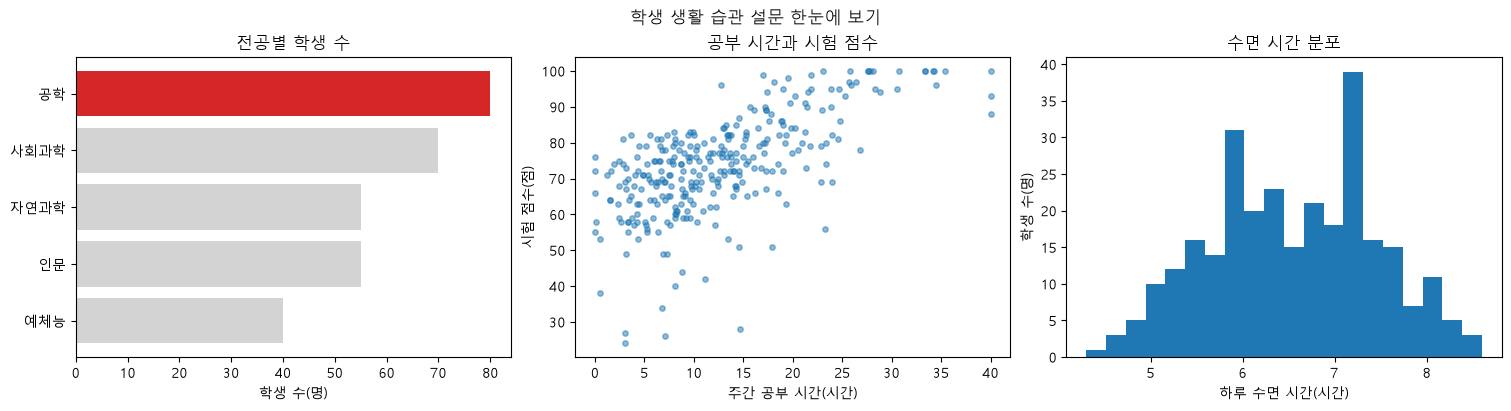

In [17]:
# 설명: 코드가 길지만 axes[0], axes[1], axes[2] 세 묶음으로 나눠 읽는다.
# 설명: 앞에서 만든 변수를 다시 쓴다. 왼쪽은 2)의 colors, 오른쪽은 앞 셀의 sleep이다.
# 설명: 칸이 세 개라 figsize를 (15, 4)로 옆으로 넓혔다.
# 설명: 실행 후 왼쪽은 공학 80명, 가운데는 r = 0.65의 오른쪽 위로 향하는 점들, 오른쪽은 평균 6.55시간 부근의 좌우가 비슷한 모양을 짚는다.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout='constrained')
axes[0].barh(major_count_sorted.index, major_count_sorted.values, color=colors)
axes[0].set_title('전공별 학생 수')
axes[0].set_xlabel('학생 수(명)')
axes[1].scatter(students['study_hours'], students['exam_score'], s=15, alpha=0.5)
axes[1].set_title('공부 시간과 시험 점수')
axes[1].set_xlabel('주간 공부 시간(시간)')
axes[1].set_ylabel('시험 점수(점)')
axes[2].hist(sleep, bins=20)
axes[2].set_title('수면 시간 분포')
axes[2].set_xlabel('하루 수면 시간(시간)')
axes[2].set_ylabel('학생 수(명)')
fig.suptitle('학생 생활 습관 설문 한눈에 보기')
plt.show()

* 세 칸은 비교·관계·분포라는 서로 다른 질문에 답한다. 축의 단위가 달라 sharey는 쓰지 않았다.
* 한 장에 모으면 보고서·발표 자료에 그림 하나로 넣을 수 있다. 저장하는 방법은 6)에서 본다.

#### <b>6) 4)의 그림을 png로 저장하고 폴더에서 열어 보기</b>

* <b>fig.savefig('경로')</b>: Figure를 파일로 저장한다. 확장자(.png, .svg)로 파일 형식이 정해진다.
* savefig는 폴더를 만들어 주지 않는다. 없는 폴더에 저장하면 FileNotFoundError가 난다.
  * <b>os.makedirs('output', exist_ok=True)</b>: 노트북과 같은 폴더 안에 output 폴더를 만든다. 이미 있으면 그냥 넘어간다.

In [18]:
# 설명: 출력이 없는 것이 정상이다. 왼쪽 탐색기에서 05_꾸미기 안에 output 폴더가 생겼는지 본다.
# 설명: 'output'은 노트북 위치를 기준으로 한 경로다.
# 설명: exist_ok=True가 없으면 다시 실행할 때 FileExistsError가 난다.
import os

os.makedirs('output', exist_ok=True)

* 4)의 2×2 그림을 다시 그리고, <b>plt.show() 앞에서</b> 저장한다.
  * <b>dpi=200</b>: 1인치에 점 200개. 숫자가 클수록 확대해도 선명하지만 파일이 커진다.
  * <b>bbox_inches='tight'</b>: 그림 둘레의 빈 여백을 잘라 내고 글자가 잘리지 않게 저장한다.
  * 같은 그림을 .svg로도 저장해 두 형식을 비교한다.

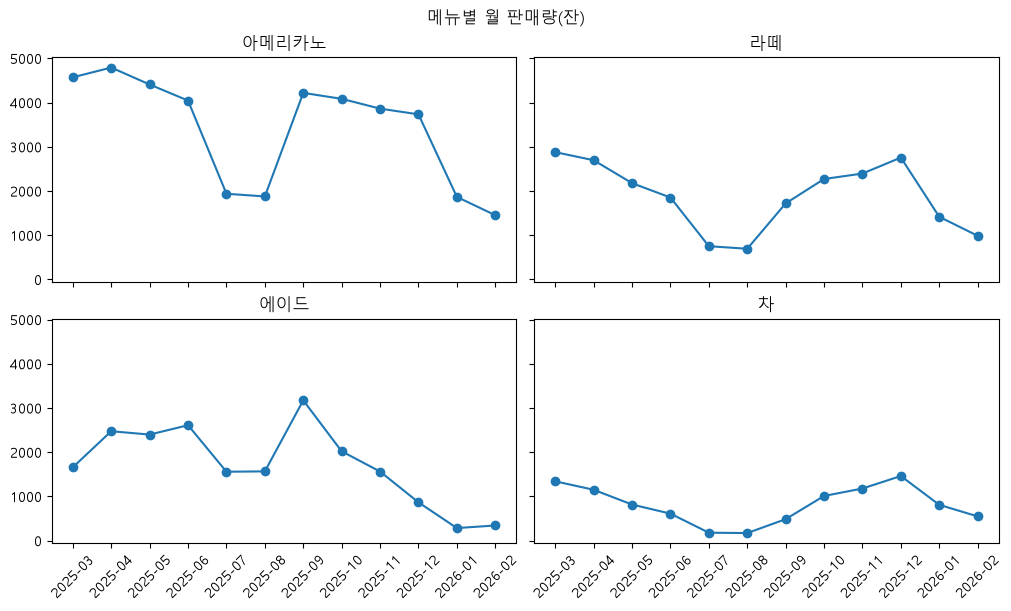

In [19]:
# 설명: 4)의 마지막 코드에 savefig 두 줄만 더했다.
# 설명: 두 줄이 plt.show() 앞에 있는 것을 짚어 둔다. 뒤에서 순서를 바꾼 경우를 보여 준다.
# 설명: 실행 후 화면 그림은 4)와 같고, 저장되었다는 표시는 나오지 않는다. 다음 셀에서 확인한다.
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey=True, layout='constrained')
axes[0, 0].plot(menu_by_month.index, menu_by_month['americano'], marker='o')
axes[0, 0].set_title('아메리카노')
axes[0, 1].plot(menu_by_month.index, menu_by_month['latte'], marker='o')
axes[0, 1].set_title('라떼')
axes[1, 0].plot(menu_by_month.index, menu_by_month['ade'], marker='o')
axes[1, 0].set_title('에이드')
axes[1, 1].plot(menu_by_month.index, menu_by_month['tea'], marker='o')
axes[1, 1].set_title('차')
axes[1, 0].tick_params(axis='x', labelrotation=45)
axes[1, 1].tick_params(axis='x', labelrotation=45)
fig.suptitle('메뉴별 월 판매량(잔)')
fig.savefig('output/menu.png', dpi=200, bbox_inches='tight')
fig.savefig('output/menu.svg', bbox_inches='tight')
plt.show()

* 저장된 파일을 확인한다.
  * <b>os.listdir('output')</b>: 폴더 안 파일 이름 목록
  * <b>os.path.getsize(경로)</b>: 파일 크기(바이트)
  * <b>plt.imread(경로).shape</b>: png를 읽어 (세로 픽셀, 가로 픽셀, 색 채널 수)를 본다. 10×6인치에 dpi 200이면 약 2000×1200 픽셀이고, 여백을 잘라 조금 달라진다.
* 이 셀을 다시 실행하면 아래에서 만드는 blank.png도 목록에 함께 나온다.
* VS Code 왼쪽 탐색기에서 05_꾸미기 › output › menu.png를 눌러 열어 본다. 확대해도 글자가 선명한지 본다.

In [20]:
# 설명: 처음 실행하면 첫 줄에 menu.png와 menu.svg만 나온다. 저장된 출력에는 blank.png까지 세 개다.
# 설명: 둘째 줄은 menu.png 142884바이트, menu.svg 67167바이트다. 이 그림은 svg가 더 작다.
# 설명: 셋째 줄 (1223, 2022, 4)는 세로가 먼저다. figsize는 가로가 먼저라서 헷갈리기 쉽다.
# 설명: 4는 색 채널 수다. dpi 200 계산값 2000×1200에 가까운지 본다.
print(sorted(os.listdir('output')))
print(os.path.getsize('output/menu.png'), os.path.getsize('output/menu.svg'))
print(plt.imread('output/menu.png').shape)

['blank.png', 'menu.png', 'menu.svg']
142884 67167
(1223, 2022, 4)


* <b>plt.show()</b>가 끝나면 그림이 화면으로 나가고 '지금 그리는 Figure'가 비워진다.
  * 그 뒤에 <b>plt.savefig()</b>를 부르면 빈 새 Figure가 저장된다. 아래 셀은 일부러 순서를 바꿔 본 것이다.

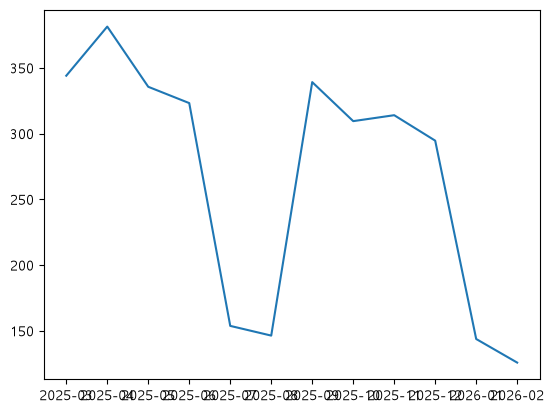

<Figure size 640x480 with 0 Axes>

In [21]:
# 설명: 일부러 틀린 순서로 쓴 셀이다. customers_by_month는 3)의 첫 셀에서 만들었다.
# 설명: 실행 전에 예고한다. 그래프가 나오고 오류도 없어서 잘 된 것처럼 보인다.
# 설명: 실행 후 그래프 아래의 글자 한 줄을 먼저 읽어 보게 한다.
fig, ax = plt.subplots()
ax.plot(customers_by_month.index, customers_by_month.values)
plt.show()
plt.savefig('output/blank.png')

* 셀 아래에 <b>&lt;Figure size 640x480 with 0 Axes&gt;</b>가 찍힌다. plt.savefig가 칸이 하나도 없는 새 Figure를 저장했다는 뜻이다.
* blank.png를 열면 아무것도 없는 흰 그림이다. 파일 크기도 menu.png보다 훨씬 작다.
* 저장 줄은 항상 plt.show() <b>앞</b>에 두고, plt 대신 <b>fig.savefig</b>처럼 저장할 Figure의 이름으로 부른다.

In [22]:
# 설명: 앞 셀의 저장 결과가 정말 비었는지 숫자로 확인한다.
# 설명: 첫 줄 2398바이트는 menu.png 142884바이트의 약 60분의 1이다. 크기 차이는 픽셀 수 때문이기도 하니 둘째 줄까지 본다.
# 설명: 둘째 줄 1.0이 이미지 값의 최솟값이다. 흰색보다 어두운 점이 하나도 없다는 뜻이다.
print(os.path.getsize('output/blank.png'))
print(plt.imread('output/blank.png').min())

2398
1.0


* 이미지 값의 최솟값이 1.0이면 모든 점이 흰색이라는 뜻이다. 그래프 선이 하나도 저장되지 않았다.
* 오늘 정리: <b>색은 강조, 축은 기준, 배치는 비교</b>. 꾸미기는 예쁘게가 아니라 읽기 쉽게 하는 일이다.